In [47]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Leitura dos dados brutos
df = pd.read_csv('/home/guirocha/city_bike_analysis/ecvd_citibike/202401-citibike-tripdata_1.csv', low_memory=False)

# 2. Conversão de datas e cálculo de duração
df['started_at'] = pd.to_datetime(df['started_at'])
df['ended_at'] = pd.to_datetime(df['ended_at'])
df['duracao_minutos'] = (df['ended_at'] - df['started_at']).dt.total_seconds() / 60

# 3. Limpeza de ruídos (Remover viagens < 1 minuto e outliers > 24 horas)
df_limpo = df[(df['duracao_minutos'] >= 1) & (df['duracao_minutos'] <= 1440)].copy()

print(f"Total de viagens válidas: {len(df_limpo)}")

Total de viagens válidas: 999626


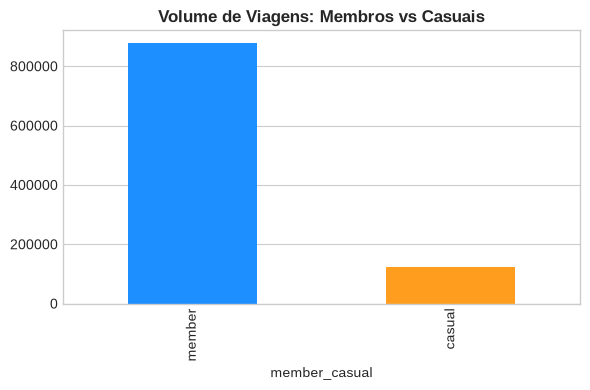

In [48]:
# Exemplo para a RV 1: Distribuição de Membros vs Casuais
plt.style.use('seaborn-v0_8-whitegrid')
cores_acessiveis = ['#1E8FFF', '#FF9E1E'] # Azul e Laranja

contagem = df_limpo['member_casual'].value_counts()
fig, ax = plt.subplots(figsize=(6, 4))
contagem.plot(kind='bar', color=cores_acessiveis, ax=ax)

ax.set_title("Volume de Viagens: Membros vs Casuais", fontweight='bold')
ax.grid(axis='x') # Remove grid vertical para não poluir
plt.tight_layout()
plt.savefig('plots/rv1_perfil.png', dpi=300)

In [49]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Leitura dos dados brutos
df = pd.read_csv('/home/guirocha/city_bike_analysis/ecvd_citibike/202401-citibike-tripdata_2.csv', low_memory=False)

# 2. Conversão de datas e cálculo de duração
df['started_at'] = pd.to_datetime(df['started_at'])
df['ended_at'] = pd.to_datetime(df['ended_at'])
df['duracao_minutos'] = (df['ended_at'] - df['started_at']).dt.total_seconds() / 60

# 3. Limpeza de ruídos (Remover viagens < 1 minuto e outliers > 24 horas)
df_limpo = df[(df['duracao_minutos'] >= 1) & (df['duracao_minutos'] <= 1440)].copy()

print(f"Total de viagens válidas: {len(df_limpo)}")

Total de viagens válidas: 887852


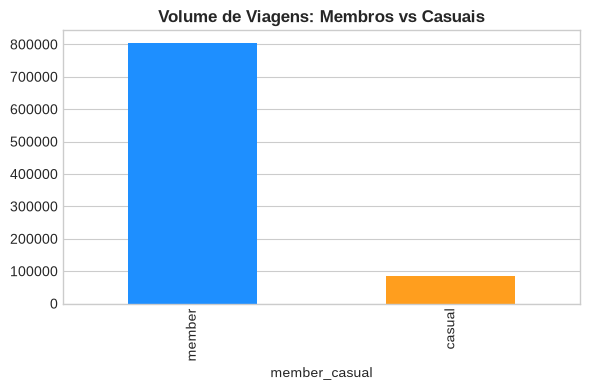

In [50]:
# Exemplo para a RV 1: Distribuição de Membros vs Casuais
plt.style.use('seaborn-v0_8-whitegrid')
cores_acessiveis = ['#1E8FFF', '#FF9E1E'] # Azul e Laranja

contagem = df_limpo['member_casual'].value_counts()
fig, ax = plt.subplots(figsize=(6, 4))
contagem.plot(kind='bar', color=cores_acessiveis, ax=ax)

ax.set_title("Volume de Viagens: Membros vs Casuais", fontweight='bold')
ax.grid(axis='x') # Remove grid vertical para não poluir
plt.tight_layout()
plt.savefig('plots/rv1_perfil.png', dpi=300)

In [51]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import plotly.express as px

# --- PREPARAÇÃO DOS DADOS ---
df = pd.read_csv("/home/guirocha/city_bike_analysis/ecvd_citibike/202401-citibike-tripdata_1.csv", low_memory=False)
df['started_at'] = pd.to_datetime(df['started_at'])
df['ended_at'] = pd.to_datetime(df['ended_at'])
df['duracao_min'] = (df['ended_at'] - df['started_at']).dt.total_seconds() / 60
df = df[(df['duracao_min'] >= 1) & (df['duracao_min'] <= 1440)].copy()

plt.style.use('seaborn-v0_8-whitegrid')
cores = ['#1E8FFF', '#FF9E1E']

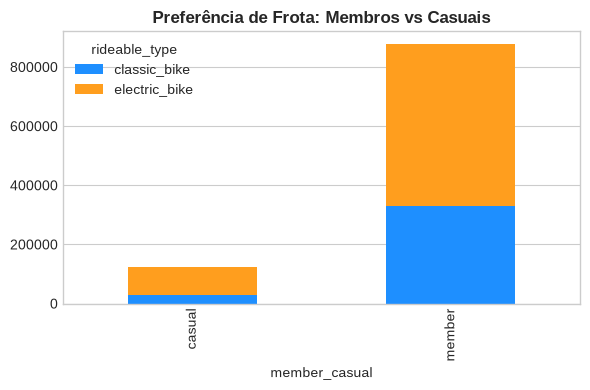

In [52]:
# --- RV 1: Matriz de Perfil e Frota ---
perfil_frota = pd.crosstab(df['member_casual'], df['rideable_type'])
fig1, ax1 = plt.subplots(figsize=(6, 4))
perfil_frota.plot(kind='bar', stacked=True, color=cores, ax=ax1)
ax1.set_title('Preferência de Frota: Membros vs Casuais', fontweight='bold')
ax1.grid(axis='x')
plt.tight_layout()
plt.show()


/tmp/ipykernel_140702/967597267.py:3: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['dia_semana'] = df['started_at'].dt.dayofweek


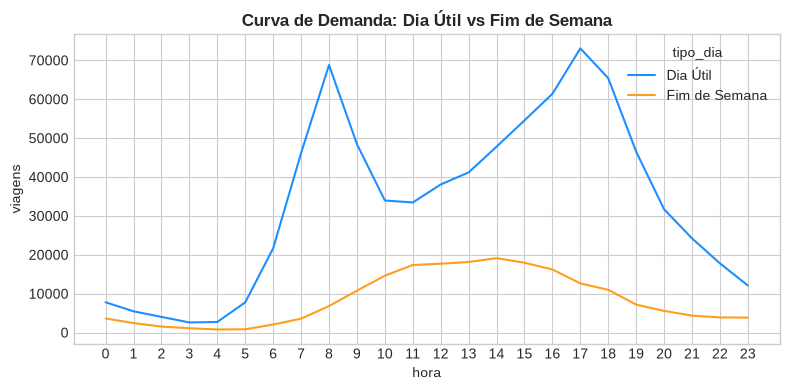

In [53]:
# --- RV 2: Séries Temporais de Demanda Horária ---
df['hora'] = df['started_at'].dt.hour
df['dia_semana'] = df['started_at'].dt.dayofweek
df['tipo_dia'] = np.where(df['dia_semana'] < 5, 'Dia Útil', 'Fim de Semana')
demanda_hora = df.groupby(['hora', 'tipo_dia']).size().reset_index(name='viagens')

fig2, ax2 = plt.subplots(figsize=(8, 4))
sns.lineplot(data=demanda_hora, x='hora', y='viagens', hue='tipo_dia', palette=cores, ax=ax2)
ax2.set_title('Curva de Demanda: Dia Útil vs Fim de Semana', fontweight='bold')
ax2.set_xticks(range(0, 24))
plt.tight_layout()
plt.show()

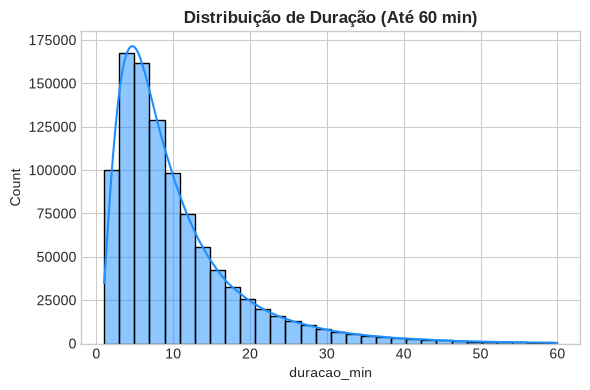

In [54]:
# --- RV 3: Distribuição de Duração ---
fig3, ax3 = plt.subplots(figsize=(6, 4))
sns.histplot(df[df['duracao_min'] <= 60]['duracao_min'], bins=30, color=cores[0], kde=True, ax=ax3)
ax3.set_title('Distribuição de Duração (Até 60 min)', fontweight='bold')
plt.tight_layout()
plt.show()

In [55]:
print(f"Latitude Min/Max:  {df['start_lat'].min():.4f} até {df['start_lat'].max():.4f}")
print(f"Longitude Min/Max: {df['start_lng'].min():.4f} até {df['start_lng'].max():.4f}")

Latitude Min/Max:  40.6334 até 40.8863
Longitude Min/Max: -74.0507 até -73.8498
